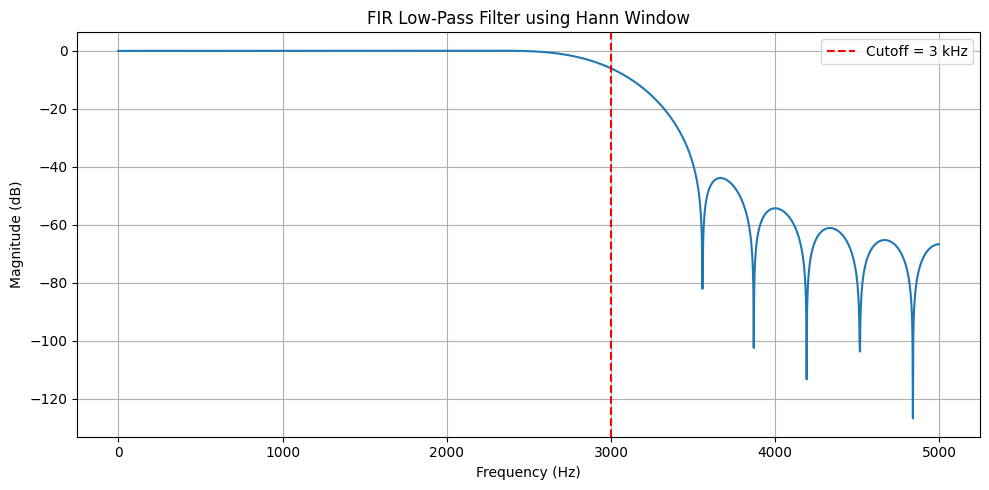

FIR filter coefficients:
[ 0.00000000e+00  2.36294439e-04 -6.22213220e-04 -1.48904646e-03
  4.55351027e-03 -5.84801114e-18 -1.16227064e-02  1.04726495e-02
  1.47629668e-02 -3.30275566e-02  1.75440334e-17  6.31702710e-02
 -5.64178020e-02 -8.95165958e-02  2.99461575e-01  6.00077307e-01
  2.99461575e-01 -8.95165958e-02 -5.64178020e-02  6.31702710e-02
  1.75440334e-17 -3.30275566e-02  1.47629668e-02  1.04726495e-02
 -1.16227064e-02 -5.84801114e-18  4.55351027e-03 -1.48904646e-03
 -6.22213220e-04  2.36294439e-04  0.00000000e+00]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz

# Step 1: Define filter parameters
Fs = 10000  # Sampling frequency = 10 kHz
Fc = 3000   # Cutoff frequency = 3 kHz
N = 31      # Number of filter taps

# Step 2: Design the FIR low-pass filter
b = firwin(
    numtaps=N,
    cutoff=Fc,
    window='hann',
    pass_zero='lowpass',
    fs=Fs
)

# Step 3: Calculate frequency response
f, H = freqz(b, worN=2048, fs=Fs)

# Step 4: Calculate magnitude response in dB
magnitude_db = 20 * np.log10(np.maximum(np.abs(H), 1e-10))

# Step 5: Plot magnitude response
plt.figure(figsize=(10, 5))
plt.plot(f, magnitude_db)
plt.axvline(Fc, color='red', linestyle='--', label='Cutoff = 3 kHz')
plt.title('FIR Low-Pass Filter using Hann Window')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude (dB)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("FIR filter coefficients:")
print(b)


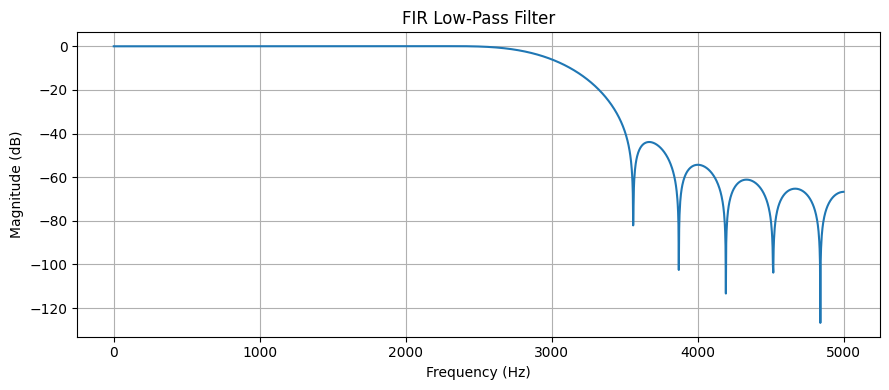

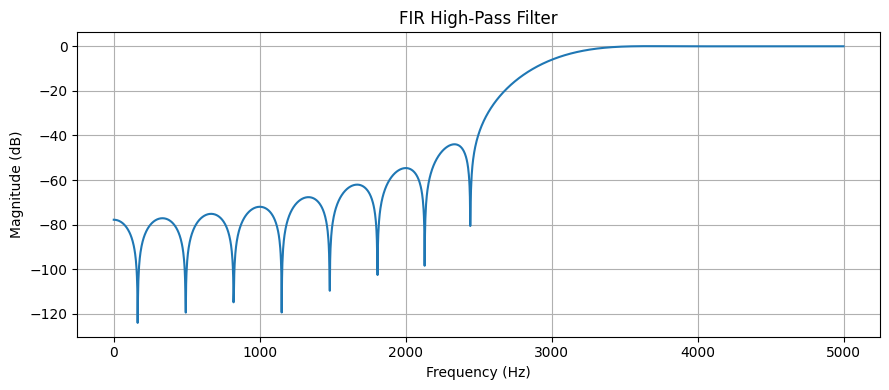

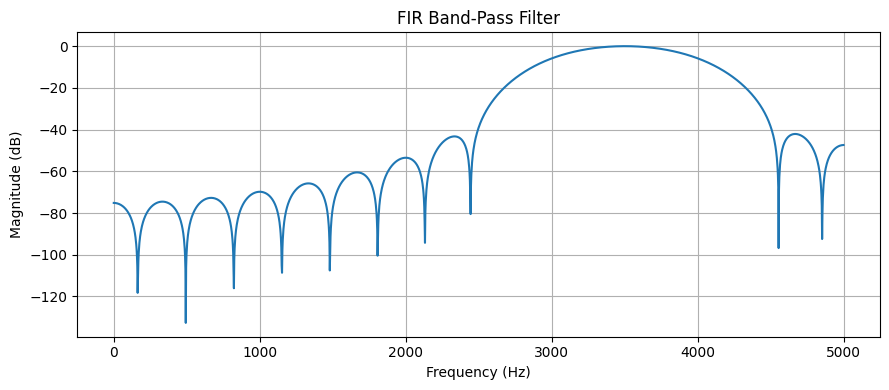

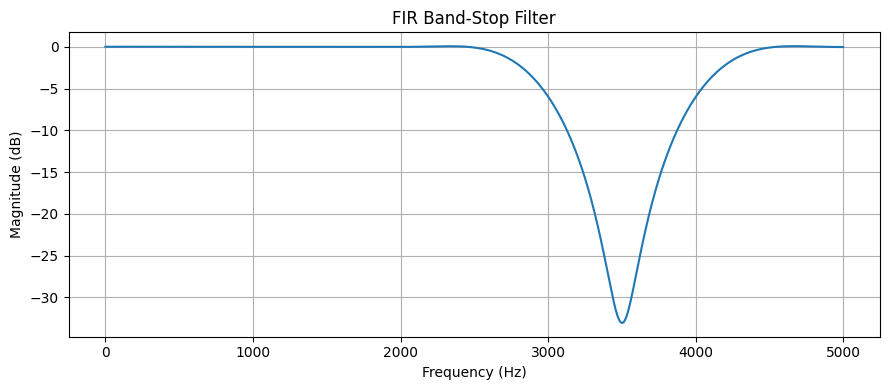

All four FIR filters designed successfully!


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz

# Filter parameters
Fs = 10000  # Sampling frequency = 10 kHz
N = 31       # Number of filter taps
Fc = 3000    # Cutoff frequency = 3 kHz

# 1. FIR Low-Pass Filter
b1 = firwin(N, Fc, window='hann', pass_zero='lowpass', fs=Fs)

# 2. FIR High-Pass Filter
b2 = firwin(N, Fc, window='hann', pass_zero='highpass', fs=Fs)

# 3. FIR Band-Pass Filter (3 kHz to 4 kHz)
b3 = firwin(N, [3000, 4000], window='hann', pass_zero='bandpass', fs=Fs)

# 4. FIR Band-Stop Filter (3 kHz to 4 kHz)
b4 = firwin(N, [3000, 4000], window='hann', pass_zero='bandstop', fs=Fs)

# Plot frequency responses
filters = [
    ("FIR Low-Pass Filter", b1),
    ("FIR High-Pass Filter", b2),
    ("FIR Band-Pass Filter", b3),
    ("FIR Band-Stop Filter", b4)
]

for title, b in filters:
    f, H = freqz(b, worN=2048, fs=Fs)
    magnitude_db = 20 * np.log10(np.maximum(np.abs(H), 1e-10))

    plt.figure(figsize=(9, 4))
    plt.plot(f, magnitude_db)
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude (dB)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

print("All four FIR filters designed successfully!")
